In [1]:
import pandas as pd 
import json
import ast
import numpy as np

Convert affiniti datastructure into useable json for evaluation

In [2]:
summaries =pd.read_csv('/Users/sebastian/AdSoLve/adsolve_utilities/evaluation_bundles/data/affiniti_dev_test_conversations/summaries.csv')

In [3]:
utterances = pd.read_csv('/Users/sebastian/AdSoLve/adsolve_utilities/evaluation_bundles/data/affiniti_dev_test_conversations/utterances.csv')

In [4]:
summaries_dict = {
    row["id"]: "\n\n".join(
        [
            entry["summary"]
            for entry in ast.literal_eval(row["summary"])
        ]
    )
    for _, row in summaries.iterrows()
}

In [5]:
utterances_dict =utterances.groupby('session_id')['message'].apply(list).to_dict()

In [6]:
# find summaries that start with "The patient did not provide"
excluded_sessions = []
for key, value in summaries_dict.items():
    if value.startswith("The patient did not provide"):
        excluded_sessions.append(key)

In [7]:
# filtered summaries and utterances
filtered_summaries_dict = {k: v for k, v in summaries_dict.items() if k not in excluded_sessions}
filtered_utterances_dict = {k: v for k, v in utterances_dict.items() if k not in excluded_sessions}

In [8]:
excluded_sessions

['ae8690ed-c516-4de1-88ab-33080b2f8cf7',
 '6f093d2d-08eb-42d4-855d-dddbae484f4e',
 'afae5b34-8fe8-4cb4-956f-7fda709dbfcb',
 '1d6989f7-21c2-4d25-a3a5-c7a45ed4f444',
 '7307b461-c6cd-4e65-ad66-581b54bf6ebf']

In [9]:
# save dicts
root = '/Users/sebastian/AdSoLve/adsolve_utilities/evaluation_bundles/data/affiniti_dev_test_conversations/'
with open(root + 'summaries.json', 'w') as f:
    json.dump(filtered_summaries_dict, f)

with open(root + 'utterances.json', 'w') as f:
    json.dump(filtered_utterances_dict, f)

Load and analyse annotations of the affiniti dev dataset completed by Sarah (Affiniti)

In [10]:
with open("summary_ratings_Sarah_2026-10-06.json") as f:
    sarah_ratings = json.load(f)

item_names = [entry["item"] for entry in sarah_ratings["sessions"][0]["ratings"]]


In [11]:
def get_item_index(item_name):
    try:
        return item_names.index(item_name) + 1  # +1 because we want item_1, item_2, etc.
    except ValueError:
        return None

df_ratings = pd.DataFrame([
    {
        "session_id": s["session_id"],
        **{f"item_{get_item_index(r['item'])}": r["score"] for r in s["ratings"]},
        "comment": s["comment"],
    }
    for s in sarah_ratings["sessions"]
])


In [12]:
df_rating_means = pd.DataFrame({
    "session_id": df_ratings["session_id"],
    "fc_rating_mean": df_ratings[["item_1", "item_2"]].mean(axis=1),
    "coherence_rating_mean": df_ratings[["item_3", "item_4"]].mean(axis=1),
    "meaning_preservation_rating_mean": df_ratings[["item_5", "item_6"]].mean(axis=1),
})


In [13]:
from sqlalchemy import create_engine

engine = create_engine("postgresql+psycopg://sebastian@localhost:5432/adsolve")
df_metrics = pd.read_sql("""
    select external_id, metric_id, score
    from document_metric_scores dms
    join metric_scores ms on dms.metric_score_id = ms.id
    join documents doc on dms.document_id = doc.id
    where document_id in (
        select id from documents
        where dataset_id = (select id from datasets where name = 'dev_test_conversation-09-26')
    )
""", engine)

df_metrics_means = (
    df_metrics.pivot(index="external_id", columns="metric_id", values="score")
      .reset_index()
      .rename(columns={"external_id": "session_id"})
)
df_metrics_means.columns.name = None

In [14]:
df_compare = df_rating_means.merge(df_metrics_means, on="session_id", how="inner")

In [15]:
df_compare

,session_id,fc_rating_mean,coherence_rating_mean,meaning_preservation_rating_mean,fc_document,intra_nli,mhic
0,34c91f23-243e-4784-a21e-eb7c2acd2402,4.5,4.0,4.0,0.963946,0.938524,0.557958
1,246f6df5-db90-46a2-89c9-139f81d1da23,3.5,3.0,3.0,0.875075,0.667368,0.539517
2,8b64cf09-872b-47b0-b233-5f6c7994c84e,3.5,3.5,3.5,0.988781,0.996282,0.524334
3,34e15756-6ac9-4529-ab6c-fd150780d8a0,2.0,3.5,3.5,0.971479,0.987915,0.565648


In [16]:
rating_cols = ["fc_rating_mean", "coherence_rating_mean", "meaning_preservation_rating_mean"]
metric_cols = ["fc_document", "intra_nli", "mhic"]

corr = df_compare[rating_cols + metric_cols].corr(method="spearman")
corr.loc[rating_cols, metric_cols]


,fc_document,intra_nli,mhic
fc_rating_mean,-0.316228,-0.316228,-0.316228
coherence_rating_mean,0.316228,0.316228,0.316228
meaning_preservation_rating_mean,0.316228,0.316228,0.316228


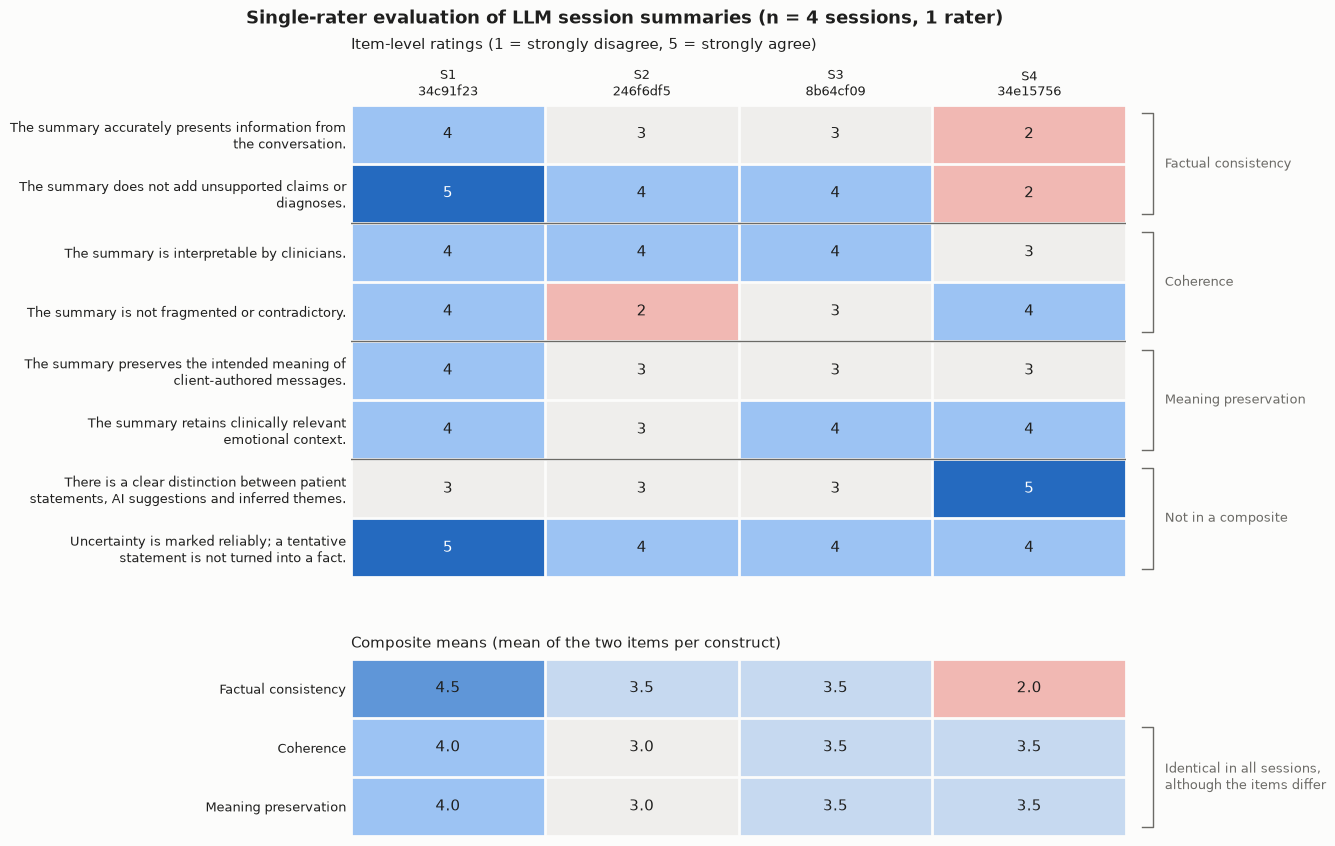

In [17]:
import textwrap
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize

# Constructs as used for the composite means above; items 7-8 are rated but not part of any composite.
constructs = [
    ("Factual consistency", ["item_1", "item_2"]),
    ("Coherence", ["item_3", "item_4"]),
    ("Meaning preservation", ["item_5", "item_6"]),
    ("Not in a composite", ["item_7", "item_8"]),
]
composites = constructs[:3]
session_labels = [f"S{i + 1}\n{sid[:8]}" for i, sid in enumerate(df_ratings["session_id"])]

# Diverging Likert scale: disagree (red) <- neutral (gray) -> agree (blue).
# Continuous so that composite means like 3.5 sit between the neighbouring scale points.
likert_colors = ["#c93a3a", "#f2b8b3", "#f0efec", "#9ec5f4", "#256abf"]
likert_cmap = LinearSegmentedColormap.from_list("likert", likert_colors)
likert_norm = Normalize(vmin=1, vmax=5)
INK, INK_MUTED, SURFACE = "#1f1f1e", "#6b6a66", "#fcfcfb"

def ink_for(score):
    return "white" if score < 1.5 or score > 4.5 else INK

def draw_grid(ax, values, row_labels, fmt):
    ax.imshow(values, cmap=likert_cmap, norm=likert_norm, aspect="auto")
    for (r, c), v in np.ndenumerate(values):
        ax.text(c, r, fmt(v), ha="center", va="center", fontsize=11, color=ink_for(v))
    ax.set_yticks(range(len(row_labels)), row_labels, fontsize=9, color=INK)
    ax.set_xticks(range(values.shape[1]), session_labels, fontsize=9, color=INK)
    ax.xaxis.tick_top()
    ax.tick_params(length=0)
    # Thin surface-coloured gaps between cells
    ax.set_xticks(np.arange(-0.5, values.shape[1]), minor=True)
    ax.set_yticks(np.arange(-0.5, values.shape[0]), minor=True)
    ax.grid(which="minor", color=SURFACE, linewidth=2)
    ax.tick_params(which="minor", length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)

def bracket(ax, first_row, last_row, label, n_cols):
    x = n_cols - 0.5 + 0.08
    xlim, ylim = ax.get_xlim(), ax.get_ylim()
    ax.plot([x, x + 0.06, x + 0.06, x], [first_row - 0.35, first_row - 0.35, last_row + 0.35, last_row + 0.35],
            color=INK_MUTED, linewidth=1, clip_on=False)
    ax.text(x + 0.12, (first_row + last_row) / 2, label, ha="left", va="center",
            fontsize=9, color=INK_MUTED, clip_on=False)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

def group_separators(ax, sizes, labels, n_cols):
    row = 0
    for size, label in zip(sizes, labels):
        bracket(ax, row, row + size - 1, label, n_cols)
        row += size
        if row < sum(sizes):
            ax.axhline(row - 0.5, color=INK_MUTED, linewidth=1)

item_cols = [col for _, cols in constructs for col in cols]
item_values = df_ratings[item_cols].to_numpy().T
item_labels = [textwrap.fill(item_names[int(c.split("_")[1]) - 1], 48) for c in item_cols]
composite_values = np.array([df_ratings[cols].mean(axis=1).to_numpy() for _, cols in composites])

fig, (ax_items, ax_comp) = plt.subplots(
    2, 1, figsize=(10, 9.5), gridspec_kw={"height_ratios": [8, 3], "hspace": 0.25}, facecolor=SURFACE
)

draw_grid(ax_items, item_values, item_labels, lambda v: f"{v:.0f}")
group_separators(ax_items, [len(cols) for _, cols in constructs], [name for name, _ in constructs], len(session_labels))
ax_items.set_title("Item-level ratings (1 = strongly disagree, 5 = strongly agree)",
                   loc="left", fontsize=11, color=INK, pad=40)

draw_grid(ax_comp, composite_values, [name for name, _ in composites], lambda v: f"{v:.1f}")
ax_comp.set_xticklabels([])
# Flag constructs whose composite means coincide in every session
for i in range(len(composites)):
    for j in range(i + 1, len(composites)):
        if np.allclose(composite_values[i], composite_values[j]):
            bracket(ax_comp, i, j, "Identical in all sessions,\nalthough the items differ", len(session_labels))
ax_comp.set_title("Composite means (mean of the two items per construct)",
                  loc="left", fontsize=11, color=INK, pad=8)

fig.suptitle("Single-rater evaluation of LLM session summaries (n = 4 sessions, 1 rater)",
             x=0.02, ha="left", fontsize=13, fontweight="bold", color=INK)

fig.savefig("sarah_ratings_overview.png", dpi=200, bbox_inches="tight", facecolor=SURFACE)
fig.savefig("sarah_ratings_overview.pdf", bbox_inches="tight", facecolor=SURFACE)
plt.show()


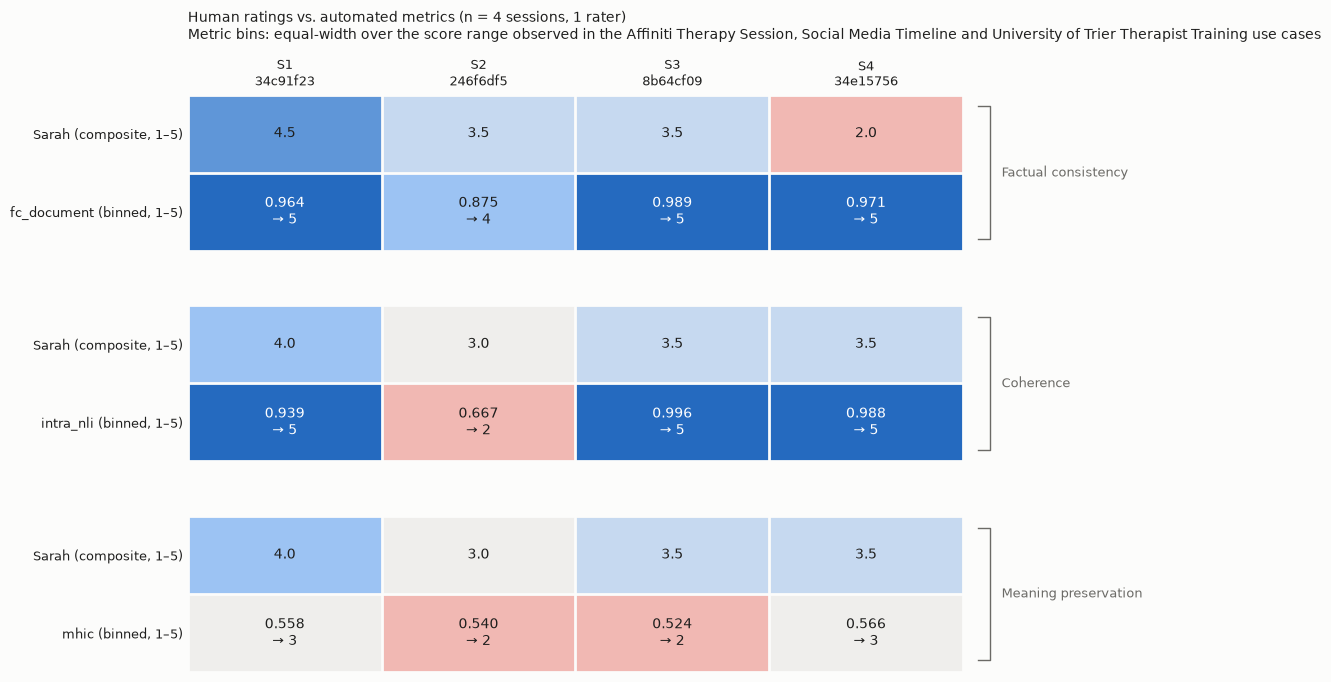

In [21]:
fig, axes = plt.subplots(
    len(pairs), 1, figsize=(10, 7.5), facecolor=SURFACE,
    gridspec_kw={"hspace": 0.35},  # gap between aspects; increase for more separation
)

for k, (ax, (construct, _, _)) in enumerate(zip(axes, pairs)):
    block = colour_values[2 * k: 2 * k + 2]
    ax.imshow(block, cmap=likert_cmap, norm=likert_norm, aspect="auto")
    for (r, c), v in np.ndenumerate(block):
        ax.text(c, r, text_rows[2 * k + r][c], ha="center", va="center", fontsize=10, color=ink_for(v))
    ax.set_yticks(range(2), row_labels[2 * k: 2 * k + 2], fontsize=9, color=INK)
    # Session labels only above the first aspect
    ax.set_xticks(range(len(pair_labels)), pair_labels if k == 0 else [], fontsize=9, color=INK)
    ax.xaxis.tick_top()
    ax.tick_params(length=0)
    ax.set_xticks(np.arange(-0.5, block.shape[1]), minor=True)
    ax.set_yticks(np.arange(-0.5, block.shape[0]), minor=True)
    ax.grid(which="minor", color=SURFACE, linewidth=2)
    ax.tick_params(which="minor", length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    bracket(ax, 0, 1, construct, len(pair_labels))

axes[0].set_title("Human ratings vs. automated metrics (n = 4 sessions, 1 rater)\n"
                  "Metric bins: equal-width over the score range observed in the Affiniti Therapy Session, Social Media Timeline and University of Trier Therapist Training use cases",
                  loc="left", fontsize=10, color=INK, pad=40)
fig.savefig("ratings_vs_metrics.png", dpi=200, bbox_inches="tight", facecolor=SURFACE)
fig.savefig("ratings_vs_metrics.pdf", bbox_inches="tight", facecolor=SURFACE)
plt.show()


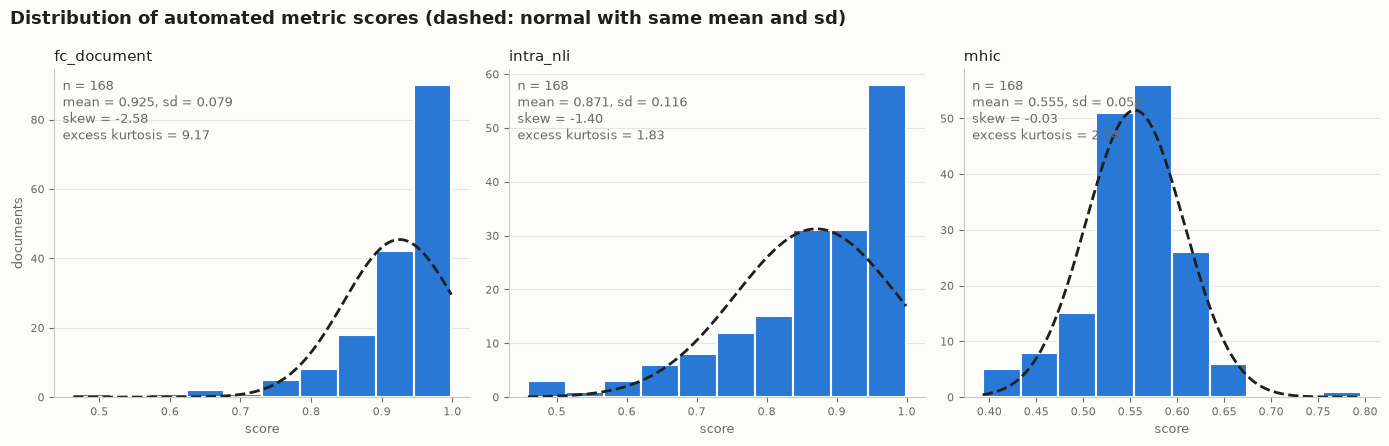

In [22]:
fig, axes = plt.subplots(1, len(metric_cols), figsize=(14, 4.5), facecolor=SURFACE)

for ax, metric in zip(axes, metric_cols):
    scores = df_ref.loc[df_ref["metric_id"] == metric, "score"]

    counts, edges, _ = ax.hist(scores, bins=10, color="#2a78d6", edgecolor=SURFACE, linewidth=1.5)

    # Normal curve with the same mean/sd, scaled to counts, as a reference shape
    mu, sd = scores.mean(), scores.std()
    x = np.linspace(edges[0], edges[-1], 200)
    pdf = np.exp(-0.5 * ((x - mu) / sd) ** 2) / (sd * np.sqrt(2 * np.pi))
    ax.plot(x, pdf * len(scores) * (edges[1] - edges[0]), color=INK, linewidth=2, linestyle="--")

    ax.text(0.02, 0.97,
            f"n = {len(scores)}\nmean = {mu:.3f}, sd = {sd:.3f}\nskew = {scores.skew():.2f}\nexcess kurtosis = {scores.kurt():.2f}",
            transform=ax.transAxes, ha="left", va="top", fontsize=9, color=INK_MUTED)

    ax.set_title(metric, loc="left", fontsize=11, color=INK)
    ax.set_xlabel("score", fontsize=9, color=INK_MUTED)
    ax.set_facecolor(SURFACE)
    ax.tick_params(colors=INK_MUTED, labelsize=8)
    ax.grid(axis="y", color="#e6e5e1", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color("#c9c8c3")

axes[0].set_ylabel("documents", fontsize=9, color=INK_MUTED)
fig.suptitle("Distribution of automated metric scores (dashed: normal with same mean and sd)",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig("metric_distributions.png", dpi=200, bbox_inches="tight", facecolor=SURFACE)
plt.show()


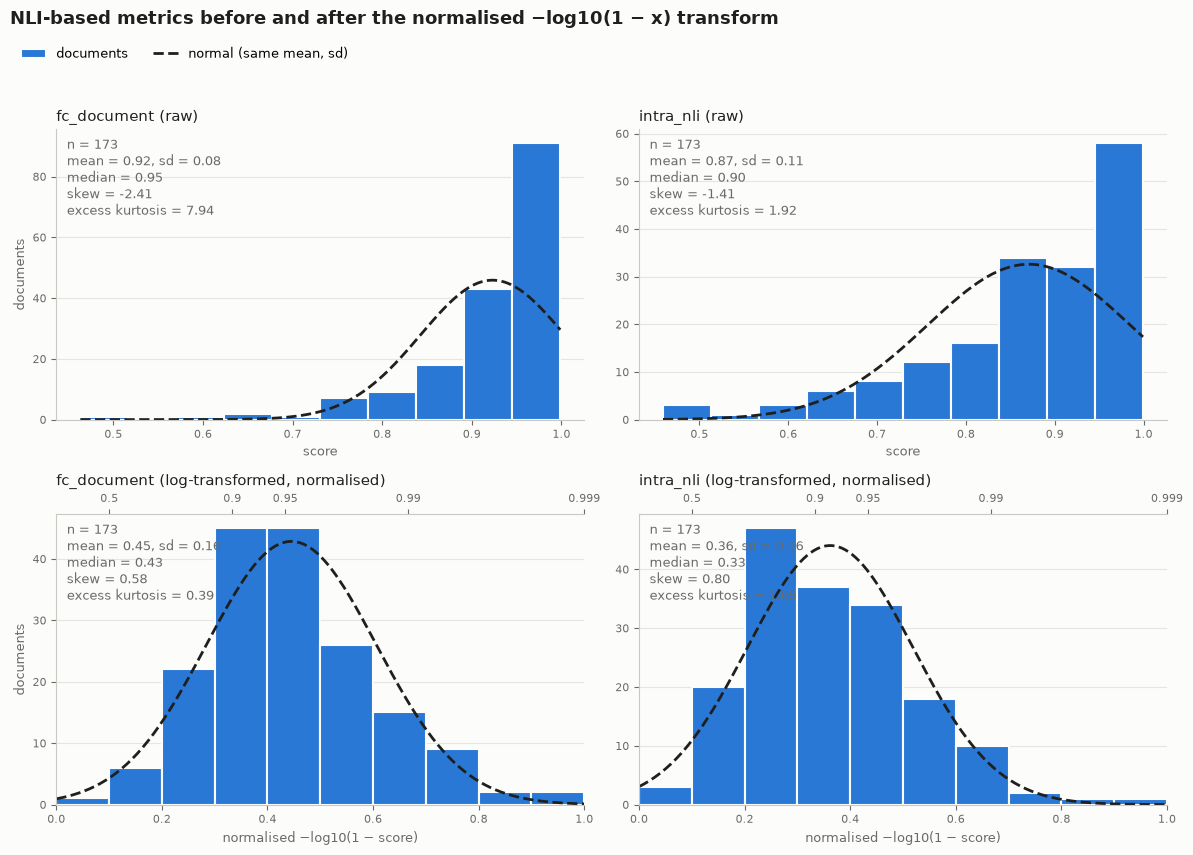

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

INK, INK_MUTED, SURFACE = "#1f1f1e", "#6b6a66", "#fcfcfb"
BAR = "#2a78d6"

# --- Reference scores from the other use cases -------------------------------------------------
reference_datasets = {
    "Affiniti therapy conversations": "Affiniti",   # "... sample" is a subset of this one, so it's left out
    "CLPsych 2025": "Social media",
    "Trier example data": "Trier",
    "Trier example data (10 samples)": "Trier",
}
excluded_docs = {("Trier example data (10 samples)", "doc-004")}  # empty LLM summary, failed generation
skewed_metrics = ["fc_document", "intra_nli"]

df_ref = pd.read_sql("""
    select ds.name as dataset, doc.external_id, ms.metric_id, dms.score
    from document_metric_scores dms
    join metric_scores ms on dms.metric_score_id = ms.id
    join documents doc on dms.document_id = doc.id
    join datasets ds on doc.dataset_id = ds.id
    where ds.name = any(%(datasets)s) and ms.metric_id = any(%(metrics)s)
""", engine, params={"datasets": list(reference_datasets), "metrics": skewed_metrics})
df_ref = df_ref[[(d, e) not in excluded_docs for d, e in zip(df_ref["dataset"], df_ref["external_id"])]]
df_ref["use_case"] = df_ref["dataset"].map(reference_datasets)

# --- Transform ---------------------------------------------------------------------------------
def nines_normalised(x, eps=1e-3):
    """-log10(1 - x) rescaled to [0, 1]: 0 -> 0, 0.9 -> 0.33, 0.99 -> 0.67, >= 1 - eps -> 1."""
    x = np.clip(x, 0, 1 - eps)
    return -np.log10(1 - x) / -np.log10(eps)

# --- Plot helpers ------------------------------------------------------------------------------
def style_axis(ax, title, xlabel):
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.set_xlabel(xlabel, fontsize=9, color=INK_MUTED)
    ax.set_facecolor(SURFACE)
    ax.tick_params(colors=INK_MUTED, labelsize=8)
    ax.grid(axis="y", color="#e6e5e1", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color("#c9c8c3")

def hist_with_normal(ax, values, edges):
    """Histogram plus a normal curve with the same mean and sd, scaled to counts."""
    ax.hist(values, bins=edges, color=BAR, edgecolor=SURFACE, linewidth=1.5, label="documents")
    mu, sd = values.mean(), values.std()
    x = np.linspace(edges[0], edges[-1], 300)
    pdf = np.exp(-0.5 * ((x - mu) / sd) ** 2) / (sd * np.sqrt(2 * np.pi))
    ax.plot(x, pdf * len(values) * (edges[1] - edges[0]), color=INK, linewidth=2, linestyle="--",
            label="normal (same mean, sd)")
    ax.text(0.02, 0.97,
            f"n = {len(values)}\nmean = {mu:.2f}, sd = {sd:.2f}\nmedian = {values.median():.2f}\n"
            f"skew = {values.skew():.2f}\nexcess kurtosis = {values.kurt():.2f}",
            transform=ax.transAxes, ha="left", va="top", fontsize=9, color=INK_MUTED)

# --- Figure ------------------------------------------------------------------------------------
fig, axes = plt.subplots(2, len(skewed_metrics), figsize=(12, 8.5), facecolor=SURFACE)

for col, metric in enumerate(skewed_metrics):
    raw = df_ref.loc[df_ref["metric_id"] == metric, "score"].reset_index(drop=True)
    transformed = pd.Series(nines_normalised(raw.to_numpy()))

    # Raw: 10 bins over the observed range
    hist_with_normal(axes[0, col], raw, np.linspace(raw.min(), raw.max(), 11))
    style_axis(axes[0, col], f"{metric} (raw)", "score")

    # Transformed: 10 bins over the fixed 0-1 range
    hist_with_normal(axes[1, col], transformed, np.linspace(0, 1, 11))
    style_axis(axes[1, col], f"{metric} (log-transformed, normalised)", "normalised −log10(1 − score)")
    axes[1, col].set_xlim(0, 1)

    # Raw-score reference ticks on the transformed axis, so readers can map back
    ref_scores = np.array([0.5, 0.9, 0.95, 0.99, 0.999])
    secax = axes[1, col].secondary_xaxis("top")
    secax.set_xticks(nines_normalised(ref_scores), [f"{s:g}" for s in ref_scores], fontsize=8, color=INK_MUTED)
    secax.tick_params(colors=INK_MUTED)
    secax.spines["top"].set_color("#c9c8c3")

for row in range(2):
    axes[row, 0].set_ylabel("documents", fontsize=9, color=INK_MUTED)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper left", bbox_to_anchor=(0.01, 0.97), ncol=2, frameon=False, fontsize=9)
fig.suptitle("NLI-based metrics before and after the normalised −log10(1 − x) transform",
             x=0.01, y=1.0, ha="left", fontsize=13, fontweight="bold", color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig("nli_metrics_transformed.png", dpi=200, bbox_inches="tight", facecolor=SURFACE)
plt.show()


Qualitative feedback

In [29]:
sarah_comments = [item['comment'] for item in sarah_ratings["sessions"]]

In [30]:
sarah_comments

["it would be valuable to include the underlying fear of being jumped/ attacked in the problem section for the question about the clear distinction between patient statements, AI suggestions etc, can we add a not applicable option? as it wasn't relevant for this example (if I have understood the question!!)",
 'the summary is quite limited in information, the outcome should include information that the patient found the decisional balance exercise challenging (not sure if the AI would recognise this?), struggling to see how taking action themselves will benefit long term (e.g. "taping over a broken structure"(- not likely to have had much therapeutic benefit and probably needing follow up in a face-to-cae context.',
 'the summary is accurate in terms of the content of the discussion but misses that the patient jumped around from activity to activity, starting with box breathing, wanting to discuss the check ins, wanting to just talk, wanting to discuss a situation at work and then term